"Do more popular books receive better ratings?"

See whether books that are more popular tend to have higher average ratings

Using:
* ratings_count
* average_rating

In [84]:
import pandas as pd

books = pd.read_csv("../data/processed/sampled_books.csv")

# remove all other columns except for ratings_count, average_rating
books = books[['ratings_count', 'average_rating']]

# shape before removing invalid data
before = books.shape

# convert to numeric
for col in ["ratings_count", "average_rating"]:
    books[col] = pd.to_numeric(books[col], errors="coerce")

# remove books with zero ratings and books outside of ratings range
books = books[(books['ratings_count'] > 0) & (books["average_rating"].between(1.0, 5.0))]

# shape after removing invalid data
after = books.shape

print(f'Removed {before[0] - after[0]} rows of invalid data. Shape is now {after}')


Removed 649 rows of invalid data. Shape is now (117384, 2)


In [85]:
print("DESCRIPTIVE STATISTICS")
print("Ratings Count")
print(f'\tMean = {books["ratings_count"].mean()}')
print(f'\tMedian = {books["ratings_count"].median()}')
print(f'\tSTD = {books["ratings_count"].std()}')

print("Average Rating")
print(f'\tMean = {books["average_rating"].mean()}')
print(f'\tMedian = {books["average_rating"].median()}')
print(f'\tSTD = {books["average_rating"].mean()}')


DESCRIPTIVE STATISTICS
Ratings Count
	Mean = 473.43950623594355
	Median = 21.0
	STD = 17618.860307563624
Average Rating
	Mean = 3.8781768384106865
	Median = 3.92
	STD = 3.8781768384106865


Scatter Plot


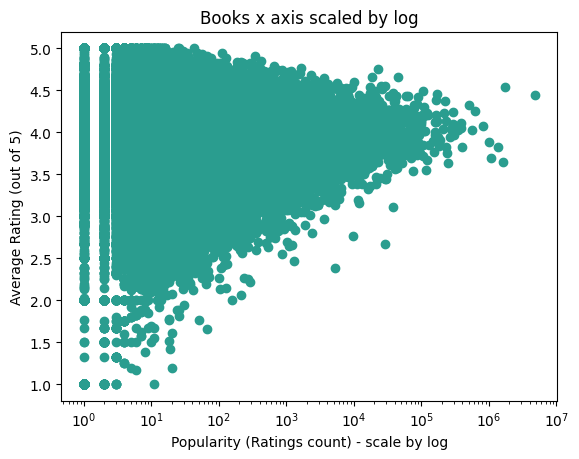

In [86]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(books["ratings_count"], books["average_rating"], color="#2A9D8F")
plt.xscale("log")
plt.xlabel("Popularity (Ratings count) - scale by log")
plt.ylabel("Average Rating (out of 5)")
plt.title("Books x axis scaled by log")
print("Scatter Plot")
plt.show()


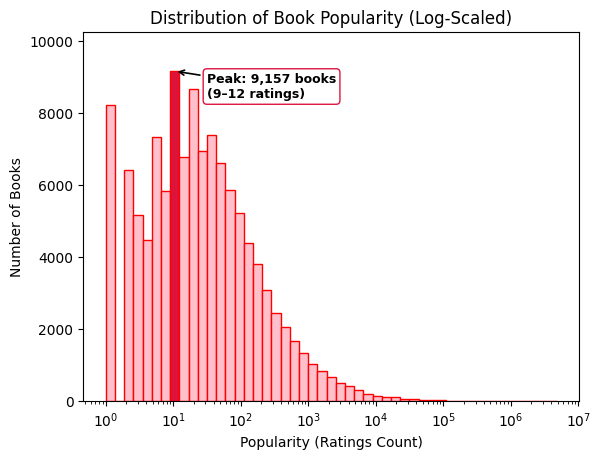

In [ ]:
bins = np.logspace(0, np.log10(books["ratings_count"].max()), 50)
counts, bin_edges, patches = plt.hist(books["ratings_count"], bins=bins, color="pink", edgecolor="red")

max_idx = np.argmax(counts)
max_count = int(counts[max_idx])
bin_start = bin_edges[max_idx]
bin_end = bin_edges[max_idx + 1]

patches[max_idx].set_facecolor("crimson")
bar_center = np.sqrt(bin_start * bin_end)
plt.annotate(
    f"Peak: {max_count:,} books\n({bin_start:.0f}–{bin_end:.0f} ratings)",
    xy=(bar_center, max_count),               
    xytext=(bar_center * 3, max_count * 0.92), 
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="crimson", lw=1)
)

plt.xscale("log")
plt.xlabel("Popularity (Ratings Count)")
plt.ylim(0, max_count * 1.12)
plt.ylabel("Number of Books")
plt.title("Distribution of Book Popularity (Log-Scaled)")
plt.show()


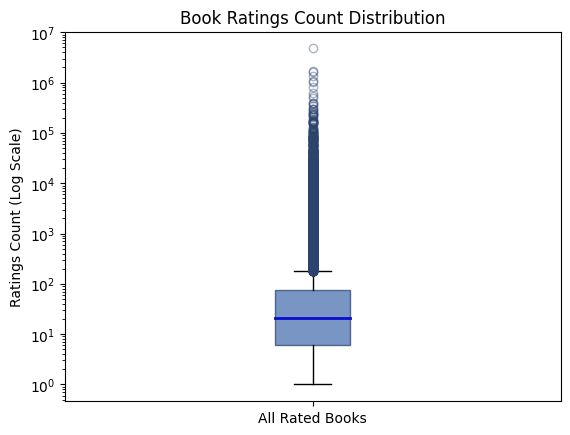

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt

bp = plt.boxplot(books["ratings_count"], patch_artist=True)

bp["boxes"][0].set(facecolor="#4C72B0", edgecolor="#2B446E", alpha=0.75)
bp["medians"][0].set(color="#0A0DCF", linewidth=2)
bp["fliers"][0].set(markeredgecolor="#2B446E", alpha=0.4)

plt.yscale("log")
plt.ylabel("Ratings Count (Log Scale)")
plt.title("Book Ratings Count Distribution")
plt.xticks([1], ["All Rated Books"])  # Replaces the blank tick mark on the x-axis
plt.show()


In [89]:
bins = [0,10,100,1000,10000,100000,10000000]

groups = pd.cut(
    books['ratings_count'],
    bins=bins
)

print(f"Mean of groups: \n{books.groupby(groups, observed=True)['average_rating'].mean()}\n")
print(f"STD of groups: \n{books.groupby(groups, observed=True)['average_rating'].std()}")


Mean of groups: 
ratings_count
(0, 10]               3.869007
(10, 100]             3.868088
(100, 1000]           3.904858
(1000, 10000]         3.947507
(10000, 100000]       4.008398
(100000, 10000000]    4.037170
Name: average_rating, dtype: float64

STD of groups: 
ratings_count
(0, 10]               0.667696
(10, 100]             0.396356
(100, 1000]           0.326374
(1000, 10000]         0.280021
(10000, 100000]       0.251981
(100000, 10000000]    0.237085
Name: average_rating, dtype: float64
